In [1216]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px 
import matplotlib.pyplot as plt

In [1217]:
df=pd.read_csv(r"D:\visual projects\export.csv")

In [1218]:
df.sample(5)

,Age recode with <1 year olds and 90+,Year of diagnosis,Sex,"Race recode (W, B, AI, API)",Primary Site,Histologic Type ICD-O-3,Combined Summary Stage with Expanded Regional Codes (2004+),"Derived AJCC Stage Group, 7th ed (2010-2015)","Derived AJCC Stage Group, 6th ed (2004-2015)",Radiation recode,"Chemotherapy recode (yes, no/unk)",RX Summ--Reg LN Examined (1998-2002),Survival months flag,Survival months,Vital status recode (study cutoff used),SEER cause-specific death classification,SEER other cause of death classification,CS tumor size (2004-2015),CS extension (2004-2015),Year of follow-up recode
12944,40-44 years,2003,Male,White,778,9663,Blank(s),Blank(s),Blank(s),Beam radiation,Yes,Blank(s),Complete dates are available and there are mor...,0243,Alive,Alive or dead of other cause,Alive or dead due to cancer,Blank(s),Blank(s),2023
3161,25-29 years,2000,Male,White,779,9663,Blank(s),Blank(s),Blank(s),None/Unknown,No/Unknown,99,Complete dates are available and there are mor...,0000,Alive,Alive or dead of other cause,Alive or dead due to cancer,Blank(s),Blank(s),2000
33944,20-24 years,2021,Female,White,778,9650,Distant site(s)/node(s) involved,Blank(s),Blank(s),None/Unknown,Yes,Blank(s),Complete dates are available and there are mor...,0035,Alive,Alive or dead of other cause,Alive or dead due to cancer,Blank(s),Blank(s),2023
50446,80-84 years,2014,Female,Black,771,9652,Distant site(s)/node(s) involved,IVB,IVB,Refused (1988+),No/Unknown,Blank(s),Complete dates are available and there are mor...,0006,Dead,Dead (attributable to this cancer dx),Alive or dead due to cancer,988,800,2014
26843,65-69 years,2006,Male,White,778,9652,Distant site(s)/node(s) involved,Blank(s),IIIA,None/Unknown,Yes,Blank(s),Complete dates are available and there are mor...,0091,Dead,Alive or dead of other cause,Dead (attributable to causes other than this c...,988,300,2013


In [1219]:
df.shape

(52083, 20)

In [1220]:
df.columns


Index(['Age recode with <1 year olds and 90+', 'Year of diagnosis', 'Sex',
       'Race recode (W, B, AI, API)', 'Primary Site',
       'Histologic Type ICD-O-3',
       'Combined Summary Stage with Expanded Regional Codes (2004+)',
       'Derived AJCC Stage Group, 7th ed (2010-2015)',
       'Derived AJCC Stage Group, 6th ed (2004-2015)', 'Radiation recode',
       'Chemotherapy recode (yes, no/unk)',
       'RX Summ--Reg LN Examined (1998-2002)', 'Survival months flag',
       'Survival months', 'Vital status recode (study cutoff used)',
       'SEER cause-specific death classification',
       'SEER other cause of death classification', 'CS tumor size (2004-2015)',
       'CS extension (2004-2015)', 'Year of follow-up recode'],
      dtype='object')

changing column's name


In [1221]:
df.rename(columns={'Age recode with <1 year olds and 90+': 'age_group'}, inplace=True)
df.rename(columns={'Race recode (W, B, AI, API)': 'race'}, inplace=True)
df.rename(columns={'Combined Summary Stage with Expanded Regional Codes (2004+)': 'summary_stage'}, inplace=True)
df.rename(columns={'Derived AJCC Stage Group, 7th ed (2010-2015)': 'ajcc_stage_7th'}, inplace=True)
df.rename(columns={'Chemotherapy recode (yes, no/unk)': 'chemo'}, inplace=True)
df.rename(columns={'Vital status recode (study cutoff used)': 'vital_status'}, inplace=True)
df.rename(columns={'SEER cause-specific death classification': 'cause_specific_death'}, inplace=True)
df.rename(columns={'SEER other cause of death classification': 'other_cause_death'}, inplace=True)
df.rename(columns={'CS tumor size (2004-2015)': 'tumor_size_raw'}, inplace=True)
df.rename(columns={'CS extension (2004-2015)': 'cs_extension_raw'}, inplace=True)
df.rename(columns={ 'Combined Summary Stage with Expanded Regional Codes (2004+)': 'summary_stage'}, inplace=True)
df.rename(columns={'Primary Site': 'primary_site_code'}, inplace=True)
df.rename(columns={'Derived AJCC Stage Group, 6th ed (2004-2015)':"stage_6th_col"},inplace=True)

In [1222]:
df.columns

Index(['age_group', 'Year of diagnosis', 'Sex', 'race', 'primary_site_code',
       'Histologic Type ICD-O-3', 'summary_stage', 'ajcc_stage_7th',
       'stage_6th_col', 'Radiation recode', 'chemo',
       'RX Summ--Reg LN Examined (1998-2002)', 'Survival months flag',
       'Survival months', 'vital_status', 'cause_specific_death',
       'other_cause_death', 'tumor_size_raw', 'cs_extension_raw',
       'Year of follow-up recode'],
      dtype='object')

ajcc_stage_7th
This is the column you renamed from:
Derived AJCC Stage Group, 7th ed (2010–2015)
It represents the patient's overall cancer stage according to the 7th edition of the AJCC staging system, for records where that staging system applies.

Examples in your data include:
I
IIA
IIB
IIIA
IIIB
IVA
IVB
UNK Stage

Derived AJCC Stage Group, 6th ed (2004-2015)
This is the same general idea, but using the 6th edition of AJCC staging.
Your data contains values such as:
IA
IIB
IIIA
IIIB
IVA
IVB
UNK Stage

So: Derived AJCC Stage Group, 6th ed = IIB
means the cancer was classified as stage IIB according to the 6th edition.

In [1223]:
df.sample(5)

,age_group,Year of diagnosis,Sex,race,primary_site_code,Histologic Type ICD-O-3,summary_stage,ajcc_stage_7th,stage_6th_col,Radiation recode,chemo,RX Summ--Reg LN Examined (1998-2002),Survival months flag,Survival months,vital_status,cause_specific_death,other_cause_death,tumor_size_raw,cs_extension_raw,Year of follow-up recode
41719,55-59 years,2000,Male,White,774,9652,Blank(s),Blank(s),Blank(s),Beam radiation,Yes,99,Complete dates are available and there are mor...,0276,Alive,Alive or dead of other cause,Alive or dead due to cancer,Blank(s),Blank(s),2023
9531,65-69 years,2021,Male,White,772,9650,Localized only,Blank(s),Blank(s),None/Unknown,No/Unknown,Blank(s),Complete dates are available and there are mor...,0000,Dead,Dead (attributable to this cancer dx),Alive or dead due to cancer,Blank(s),Blank(s),2021
33405,65-69 years,2020,Female,Black,778,9650,Regional by direct extension only,Blank(s),Blank(s),Beam radiation,Yes,Blank(s),Complete dates are available and there are mor...,0042,Alive,Alive or dead of other cause,Alive or dead due to cancer,Blank(s),Blank(s),2023
29096,65-69 years,2011,Male,White,778,9650,Distant site(s)/node(s) involved,IVB,IVB,None/Unknown,No/Unknown,Blank(s),Complete dates are available and there are mor...,0000,Dead,Dead (attributable to this cancer dx),Alive or dead due to cancer,988,800,2011
23669,75-79 years,2004,Female,White,779,9650,Distant site(s)/node(s) involved,Blank(s),IVB,None/Unknown,Yes,Blank(s),Complete dates are available and there are mor...,0000,Dead,Dead (attributable to this cancer dx),Alive or dead due to cancer,988,800,2004


In [1224]:
df['age_group'].value_counts()

age_group
20-24 years    5850
25-29 years    5632
30-34 years    4974
15-19 years    4157
35-39 years    4026
40-44 years    3708
45-49 years    3220
50-54 years    3049
55-59 years    2876
60-64 years    2714
65-69 years    2670
70-74 years    2376
75-79 years    2049
10-14 years    1609
80-84 years    1447
85-89 years     826
05-09 years     540
90+ years       259
01-04 years     100
00 years          1
Name: count, dtype: int64

In [1225]:
df["Year of diagnosis"].value_counts()

Year of diagnosis
2007    2284
2008    2278
2016    2274
2019    2256
2010    2255
2005    2237
2023    2226
2006    2218
2009    2210
2011    2195
2022    2195
2014    2172
2021    2171
2015    2165
2020    2161
2012    2156
2017    2139
2004    2132
2018    2125
2013    2107
2002    2075
2003    2068
2001    2043
2000    1941
Name: count, dtype: int64

In [1226]:
df["Sex"].value_counts()

Sex
Male      28769
Female    23314
Name: count, dtype: int64

In [1227]:
df["race"].value_counts()

race
White                            42149
Black                             6099
Asian or Pacific Islander         2892
Unknown                            652
American Indian/Alaska Native      291
Name: count, dtype: int64

In [1228]:
df["race"].value_counts()

race
White                            42149
Black                             6099
Asian or Pacific Islander         2892
Unknown                            652
American Indian/Alaska Native      291
Name: count, dtype: int64

In [1229]:
df["primary_site_code"].nunique()

136

In [1230]:
df["primary_site_code"].value_counts()

primary_site_code
778    28044
770     8365
779     6690
771     3143
773     2075
       ...  
710        1
716        1
159        1
189        1
40         1
Name: count, Length: 136, dtype: int64

In [1231]:
df["Histologic Type ICD-O-3"].value_counts()

Histologic Type ICD-O-3
9663    24943
9650    14826
9652     5416
9659     3351
9651     1516
9665      717
9667      605
9653      449
9664      219
9655       29
9654        9
9661        2
9662        1
Name: count, dtype: int64

In [1232]:
df["summary_stage"].value_counts()

summary_stage
Distant site(s)/node(s) involved     18453
Regional by direct extension only    16586
Blank(s)                              8127
Localized only                        6640
Unknown/unstaged/unspecified/DCO      2277
Name: count, dtype: int64

In [1233]:
df["summary_stage"].value_counts()

summary_stage
Distant site(s)/node(s) involved     18453
Regional by direct extension only    16586
Blank(s)                              8127
Localized only                        6640
Unknown/unstaged/unspecified/DCO      2277
Name: count, dtype: int64

In [1234]:
df["ajcc_stage_7th"].value_counts()

ajcc_stage_7th
Blank(s)     39033
IIA           2628
IVB           1599
IIB           1503
IA            1230
IIIB           935
IIIA           867
IVA            802
UNK Stage      685
IIISB          377
IB             362
II             327
I              308
IIISA          242
IV             223
IIEA           216
IIEB           170
III            147
IIIEB           73
IIIEA           54
IEA             41
IIIS            41
IIE             39
IIIESB          38
IISB            30
IIIESA          25
IISA            21
IEB             16
IIIE            14
IE              12
IIS              5
IIESA            5
IIIES            4
IIESB            4
ISB              2
ISA              2
Name: count, dtype: int64

In [1235]:
df["ajcc_stage_7th"].value_counts()

ajcc_stage_7th
Blank(s)     39033
IIA           2628
IVB           1599
IIB           1503
IA            1230
IIIB           935
IIIA           867
IVA            802
UNK Stage      685
IIISB          377
IB             362
II             327
I              308
IIISA          242
IV             223
IIEA           216
IIEB           170
III            147
IIIEB           73
IIIEA           54
IEA             41
IIIS            41
IIE             39
IIIESB          38
IISB            30
IIIESA          25
IISA            21
IEB             16
IIIE            14
IE              12
IIS              5
IIESA            5
IIIES            4
IIESB            4
ISB              2
ISA              2
Name: count, dtype: int64

In [1236]:
df["Radiation recode"].value_counts()

Radiation recode
None/Unknown                                             36748
Beam radiation                                           14170
Recommended, unknown if administered                       703
Refused (1988+)                                            269
Radiation, NOS  method or source not specified             161
Combination of beam with implants or isotopes               14
Radioactive implants (includes brachytherapy) (1988+)       10
Radioisotopes (1988+)                                        8
Name: count, dtype: int64

In [1237]:
df["chemo"].value_counts()

chemo
Yes           42543
No/Unknown     9540
Name: count, dtype: int64

In [1238]:
df["RX Summ--Reg LN Examined (1998-2002)"].value_counts()

RX Summ--Reg LN Examined (1998-2002)
Blank(s)    46024
99           3768
00           2232
01             26
98             13
02              7
97              4
03              2
09              2
13              1
95              1
14              1
90              1
96              1
Name: count, dtype: int64

In [1239]:
df["Survival months flag"].value_counts()

Survival months flag
Complete dates are available and there are more than 0 days of survival      49905
Incomplete dates are available and there cannot be zero days of follow-up     1775
Not calculated because a Death Certificate Only or Autopsy Only case           231
Complete dates are available and there are 0 days of survival                  143
Incomplete dates are available and there could be zero days of follow-up        29
Name: count, dtype: int64

In [1240]:
df["Survival months"].value_counts()

Survival months
0000    1374
0001     923
0002     709
0004     689
0003     655
        ... 
0257      84
0276      81
0281      79
0280      72
0287      68
Name: count, Length: 289, dtype: int64

In [1241]:
df["vital_status"].value_counts()

vital_status
Alive    38406
Dead     13677
Name: count, dtype: int64

In [1242]:
df["cause_specific_death"].value_counts()

cause_specific_death
Alive or dead of other cause             44236
Dead (attributable to this cancer dx)     7592
Dead (missing/unknown COD)                 255
Name: count, dtype: int64

In [1243]:
df["other_cause_death"].value_counts()

other_cause_death
Alive or dead due to cancer                                45998
Dead (attributable to causes other than this cancer dx)     5830
Dead (missing/unknown COD)                                   255
Name: count, dtype: int64

In [1244]:
df["tumor_size_raw"].value_counts()

tumor_size_raw
988         26406
Blank(s)    25674
999             2
026             1
Name: count, dtype: int64

In [1245]:
df["cs_extension_raw"].value_counts()

cs_extension_raw
Blank(s)    25674
200          9192
800          5072
100          4039
300          3780
999          1422
320          1265
210           866
310           258
330           184
110           175
220           116
230            26
120            11
305             1
315             1
325             1
Name: count, dtype: int64

In [1246]:
df["Year of follow-up recode"].value_counts()

Year of follow-up recode
2023    36559
2022     1614
2021     1130
2020     1058
2019      826
2016      801
2018      791
2015      758
2017      745
2014      739
2013      730
2010      690
2011      683
2012      641
2009      597
2007      586
2008      534
2006      515
2005      502
2004      473
2003      387
2002      321
2001      283
2000      120
Name: count, dtype: int64

In [1247]:
df.shape

(52083, 20)

In [1248]:
df.columns

Index(['age_group', 'Year of diagnosis', 'Sex', 'race', 'primary_site_code',
       'Histologic Type ICD-O-3', 'summary_stage', 'ajcc_stage_7th',
       'stage_6th_col', 'Radiation recode', 'chemo',
       'RX Summ--Reg LN Examined (1998-2002)', 'Survival months flag',
       'Survival months', 'vital_status', 'cause_specific_death',
       'other_cause_death', 'tumor_size_raw', 'cs_extension_raw',
       'Year of follow-up recode'],
      dtype='object')

In [1249]:
df.describe()

,Year of diagnosis,primary_site_code,Histologic Type ICD-O-3,Year of follow-up recode
count,52083.000000,52083.000000,52083.000000,52083.000000
mean,2011.606877,764.755851,9657.534781,2020.223566
std,6.864832,73.819481,6.099201,5.461236
min,2000.000000,19.000000,9650.000000,2000.000000
25%,2006.000000,772.000000,9650.000000,2021.000000
50%,2012.000000,778.000000,9663.000000,2023.000000
75%,2018.000000,778.000000,9663.000000,2023.000000
max,2023.000000,809.000000,9667.000000,2023.000000


In [1250]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52083 entries, 0 to 52082
Data columns (total 20 columns):
 #   Column                                Non-Null Count  Dtype 
---  ------                                --------------  ----- 
 0   age_group                             52083 non-null  object
 1   Year of diagnosis                     52083 non-null  int64 
 2   Sex                                   52083 non-null  object
 3   race                                  52083 non-null  object
 4   primary_site_code                     52083 non-null  int64 
 5   Histologic Type ICD-O-3               52083 non-null  int64 
 6   summary_stage                         52083 non-null  object
 7   ajcc_stage_7th                        52080 non-null  object
 8   stage_6th_col                         52083 non-null  object
 9   Radiation recode                      52083 non-null  object
 10  chemo                                 52083 non-null  object
 11  RX Summ--Reg LN Examined (19

# DATA CLEANING STEPS

### Step 1 Create a separate cleaned dataset 

so We check for and remove exact duplicate rows to ensure that each record is represented only once. cuz Duplicate records can bias the analysis and affect machine learning results.

In [1251]:
df_clean = df.copy()

### Step 2 Remove duplicate records

In [1252]:
print("Duplicates before:", df_clean.duplicated().sum())

Duplicates before: 1939


In [1253]:
df_clean = df_clean.drop_duplicates()

In [1254]:
print("Duplicates after:", df_clean.duplicated().sum())


Duplicates after: 0


In [1255]:
print("Shape after removing duplicates:", df_clean.shape)

Shape after removing duplicates: (50144, 20)


In [1256]:
df_clean.columns

Index(['age_group', 'Year of diagnosis', 'Sex', 'race', 'primary_site_code',
       'Histologic Type ICD-O-3', 'summary_stage', 'ajcc_stage_7th',
       'stage_6th_col', 'Radiation recode', 'chemo',
       'RX Summ--Reg LN Examined (1998-2002)', 'Survival months flag',
       'Survival months', 'vital_status', 'cause_specific_death',
       'other_cause_death', 'tumor_size_raw', 'cs_extension_raw',
       'Year of follow-up recode'],
      dtype='object')

### 2. Standardize special missing values  

diffrent missing or unknown values were represented by different text labels in the original dataset. These labels were converted to `NaN` so that missing values could be identified and handled consistently.

In [1257]:
# 3. Replace special missing values with NaN

missing_values = [
    'Blank(s)',
    'Unknown',
    'UNK Stage',
    'Unknown/unstaged/unspecified/DCO',
    'Unknown'
]

df_clean = df_clean.replace(missing_values, np.nan)


### 3.Converting Numeric Variables

Several variables were stored as text even though they represent numerical values. These columns were converted to numeric format to allow proper calculations, statistical analysis, and machine learning.

In [1258]:
# 4. Convert numeric columns to numeric
#Before cleaning, your values looked like:0088 They were stored as text (string/object). 
# This is a Pandas function that tries to convert values into numbers.
#errors='coerce'--> "If you find something that cannot be converted to a number, don't give me an error. Convert it to NaN instead."

numeric_columns = [
    'Year of diagnosis',
    'primary_site_code',
    'Histologic Type ICD-O-3',
    'Survival months',
    'Year of follow-up recode',
    'RX Summ--Reg LN Examined (1998-2002)',
    'tumor_size_raw',
    'cs_extension_raw'
]

for col in numeric_columns:
    df_clean[col] = pd.to_numeric(
        df_clean[col],
        errors='coerce'
    )

In [1259]:
print("\nMissing values:")
print(df_clean.isna().sum())


Missing values:
age_group                                   0
Year of diagnosis                           0
Sex                                         0
race                                      650
primary_site_code                           0
Histologic Type ICD-O-3                     0
summary_stage                           10129
ajcc_stage_7th                          38062
stage_6th_col                           25672
Radiation recode                            0
chemo                                       0
RX Summ--Reg LN Examined (1998-2002)    44243
Survival months flag                        0
Survival months                           216
vital_status                                0
cause_specific_death                        0
other_cause_death                           0
tumor_size_raw                          24261
cs_extension_raw                        24261
Year of follow-up recode                    0
dtype: int64


In [1260]:
# Check missing values before cleaning
print("Missing race values:", df_clean['race'].isna().sum())

Missing race values: 650


In [1261]:
df_clean.dropna(subset=['race'], inplace=True)

In [1262]:

print("\nMissing race values after cleaning:", df_clean['race'].isna().sum())


Missing race values after cleaning: 0


### Step 1  We noticed that summary_stage has missing values

The missing values in `summary_stage` were investigated by diagnosis year to determine whether the missingness was random or related to the period in which the variable was available. We also checked whether the missing values could be recovered from the AJCC staging variables.

In [1263]:
print("Missing values:", df_clean['summary_stage'].isna().sum())

Missing values: 9928


In [1264]:
print(df_clean['summary_stage'].value_counts(dropna=False))

summary_stage
Distant site(s)/node(s) involved     17593
Regional by direct extension only    15479
NaN                                   9928
Localized only                        6494
Name: count, dtype: int64


### Step 2 We checked the missing values by diagnosis year
summary_stage contains the cancer's broad stage:
Localized only
Regional by direct extension only
Distant site(s)/node(s) involved

But there were missing values.
So instead of immediately filling them, we asked: Why are these values missing? Are they randomly missing, or is there a pattern?

2000–2003: ~1,900–2,000 missing each year ❗
2004–2023: only around 80–135 missing per year

So yes, the missingness is strongly related to the year.

We checked Year of diagnosis first because the column name itself says (2004+), so year is an obvious thing to investigate. And our result showed a very strong relationship: most missing values are from 2000–2003.

### 2. We checked the missing values by diagnosis year

In [1265]:
df_clean[df_clean['summary_stage'].isna()]['Year of diagnosis'].value_counts().sort_index()

Year of diagnosis
2000    1883
2001    1987
2002    1994
2003    1964
2004     123
2005     123
2006     126
2007     115
2008     110
2009     119
2010     118
2011     109
2012     109
2013      99
2014     116
2015      89
2016     124
2017     122
2018      91
2019      85
2020      77
2021      87
2022      65
2023      93
Name: count, dtype: int64

### 3. Step 3 — We confirmed this with a cross-tab
So for 2000–2003, there are no recorded summary_stage categories at all.
That strongly suggests that summary_stage was not available or not consistently recorded during those years in this dataset.
We therefore shouldn't treat those missing values as ordinary patient-level missing data.

In [1266]:
pd.crosstab(
    df_clean['Year of diagnosis'],
    df_clean['summary_stage'],
    dropna=False
)

summary_stage,Distant site(s)/node(s) involved,Localized only,Regional by direct extension only,NaN
Year of diagnosis,,,,
2000,0,0,0,1883
2001,0,0,0,1987
2002,0,0,0,1994
2003,0,0,0,1964
2004,766,370,835,123
2005,856,368,838,123
2006,806,412,829,126
2007,899,353,859,115
2008,880,374,856,110


### Step 4: "Can we recover the missing stage from another staging column?" This is where AJCC becomes relevant.

We have three staging-related columns:
summary_stage
AJCC 7th
AJCC 6th

So we asked:
If summary_stage is missing, maybe AJCC 7th or AJCC 6th contains the patient's stage.

We selected all patients where:
missing_summary = df_clean['summary_stage'].isna()

There were: 9,928 patients

Then we checked their AJCC information.

In [1267]:
# Check how many missing summary_stage values can be recovered
# using AJCC 7th stage or AJCC 6th stage
#Imagine one patient:
#summary_stage = NaN
#AJCC 7th      = Stage III

#We know something about their stage from another column, so we can potentially use that information.
#But if we have:
#summary_stage = NaN
#AJCC 7th      = NaN
#AJCC 6th      = NaN
#then we don't know the stage, so we shouldn't guess it.

missing_summary = df_clean['summary_stage'].isna()

print("Missing summary_stage:", missing_summary.sum())

print("AJCC 7th available:", df_clean.loc[missing_summary, 'ajcc_stage_7th'].notna().sum())

print( "AJCC 6th available:",df_clean.loc[missing_summary,'stage_6th_col'].notna().sum())

Missing summary_stage: 9928
AJCC 7th available: 0
AJCC 6th available: 0


### Step 5  We discovered that AJCC couldn't recover them

The results were:

Missing summary_stage: 9928
AJCC 7th available: 0
AJCC 6th available: 0

So for all 9,928 patients:

summary_stage → missing
AJCC 7th      → missing
AJCC 6th      → missing

Therefore: We couldn't recover those missing summary_stage values from the other staging columns.
And we didn't want to simply invent a stage.

In [1268]:
null_summary_df = df_clean[df_clean['summary_stage'].isna()]

print("Number of rows with missing summary_stage:", len(null_summary_df))
print("\nMissing values distribution in other stage columns:")
#Among the rows where summary_stage is missing, how many have an AJCC 6th stage available?
#Among the rows where summary_stage is missing, how many have an AJCC 7th stage available?
print(null_summary_df[['ajcc_stage_7th', "stage_6th_col"]].isna().sum())


Number of rows with missing summary_stage: 9928

Missing values distribution in other stage columns:
ajcc_stage_7th    9928
stage_6th_col     9928
dtype: int64


In [1269]:
print(df_clean['summary_stage'].value_counts())
print("\nMissing values:", df_clean['summary_stage'].isna().sum())

summary_stage
Distant site(s)/node(s) involved     17593
Regional by direct extension only    15479
Localized only                        6494
Name: count, dtype: int64

Missing values: 9928


In [1270]:
#We're trying to understand how much AJCC 7th data is actually available and what categories it contains before deciding how to clean it.
#Counts how many patients have missing AJCC 7th stage.
print("Missing values:", df_clean['ajcc_stage_7th'].isna().sum())

print("\nValue counts:")
print(df_clean['ajcc_stage_7th'].value_counts(dropna=False))

Missing values: 37510

Value counts:
ajcc_stage_7th
NaN       37510
IIA        2459
IVB        1565
IIB        1435
IA         1210
IIIB        922
IIIA        847
IVA         791
IIISB       370
IB          356
II          322
I           296
IIISA       239
IV          218
IIEA        216
IIEB        170
III         147
IIIEB        73
IIIEA        53
IEA          41
IIIS         40
IIE          38
IIIESB       37
IISB         30
IIIESA       24
IISA         21
IEB          16
IIIE         14
IE           12
IIS           5
IIESA         5
IIIES         4
IIESB         4
ISB           2
ISA           2
Name: count, dtype: int64


In [1271]:
print("Missing values:",
      df_clean['stage_6th_col'].isna().sum())

print("\nValue counts:")
print(
    df_clean['stage_6th_col']
    .value_counts(dropna=False)
)

Missing values: 25189

Value counts:
stage_6th_col
NaN       25189
IIA        5043
IVB        3008
IIB        2860
IA         2505
IIIB       1757
IIIA       1625
IVA        1497
II          826
I           736
IB          734
IIISB       693
IV          490
IIISA       461
IIEA        430
III         346
IIEB        335
IIIEB       129
IIIESB      104
IIIEA       101
IEA          97
IIE          96
IIIS         95
IISB         64
IIIESA       63
IEB          41
IE           38
IISA         35
IIIE         27
IIS          17
IIIES        15
IIESA        12
IIESB        12
ISB           6
ISA           5
IIES          2
Name: count, dtype: int64


2000–2003  → not applicable
2004–2015  → mainly available
2016–2023  → not applicable

This makes sense because the column is explicitly:

AJCC Stage Group, 6th ed (2004-2015)

So the missing values are mostly because the 6th edition doesn't apply to those years, not because we lost patient information.

In [1272]:
print(
    df_clean[
        df_clean['stage_6th_col'].isna()
    ]['Year of diagnosis']
    .value_counts()
    .sort_index()
)

Year of diagnosis
2000    1883
2001    1987
2002    1994
2003    1964
2004     123
2005     123
2006     126
2007     115
2008     110
2009     119
2010     118
2011     110
2012     109
2013      99
2014     116
2015      89
2016    2118
2017    1979
2018    1973
2019    2051
2020    1978
2021    1972
2022    1952
2023    1981
Name: count, dtype: int64


#### Step 6 — BUT then we used summary_stage as a fallback when creating ajcc_combined

After investigating summary_stage, you created:
df_clean['ajcc_combined'] = df_clean['ajcc_stage_7th'].combine_first(
    df_clean['stage_6th_col']
)

Meaning:First choice: AJCC 7th

If AJCC 7th is missing: Second choice: AJCC 6th

So now we have one combined AJCC column.

### Step 7 — We used summary_stage as another fallback
We checked what was still missing --> Remaining true NaNs in ajcc_combined: 9928
Why?Because those 9,928 patients had:

AJCC 7th → missing
AJCC 6th → missing
summary_stage → missing

So there was literally no staging information among those three columns that we could use.

In [1273]:
#Use AJCC 7th when it exists. If AJCC 7th is missing, use AJCC 6th.
df_clean['ajcc_combined'] = df_clean['ajcc_stage_7th'].combine_first(df_clean["stage_6th_col"])

summary_to_ajcc = {
    'Localized only': 'Stage I',
    'Regional by direct extension only': 'Stage II',
    'Distant site(s)/node(s) involved': 'Stage IV'
}

df_clean['ajcc_combined'] = df_clean['ajcc_combined'].fillna(
    df_clean['summary_stage'].map(summary_to_ajcc)
)

print("Remaining true NaNs in ajcc_combined:", df_clean['ajcc_combined'].isna().sum())

Remaining true NaNs in ajcc_combined: 9928


In [1274]:
import pandas as pd

#Give me all patients for whom we still don't have an AJCC stage.
unstaged_df = df_clean[df_clean['ajcc_combined'].isna()]

#len(unstaged_df) tells us how many patients are in that group.
print(f"Total unstaged patients: {len(unstaged_df)}\n")

#"For the patients with no AJCC stage, which other columns are also missing?"
#That can help us understand whether these unstaged patients have other useful information that could help with analysis.
print("=== Missing values count in other key columns for these patients ===")
print(unstaged_df.isna().sum())

Total unstaged patients: 9928

=== Missing values count in other key columns for these patients ===
age_group                                  0
Year of diagnosis                          0
Sex                                        0
race                                       0
primary_site_code                          0
Histologic Type ICD-O-3                    0
summary_stage                           9928
ajcc_stage_7th                          9928
stage_6th_col                           9928
Radiation recode                           0
chemo                                      0
RX Summ--Reg LN Examined (1998-2002)    4064
Survival months flag                       0
Survival months                          190
vital_status                               0
cause_specific_death                       0
other_cause_death                          0
tumor_size_raw                          8572
cs_extension_raw                        8572
Year of follow-up recode                   0


Patients with known AJCC stage
        ↓
Train Random Forest
        ↓
Learn relationship between patient information and AJCC stage
        ↓
Patients with missing AJCC stage
        ↓
Predict their stage

THE IDEA : Use patients who already have an AJCC stage to train a Random Forest model, then use that model to predict the missing AJCC stages.
 AJCC 7th ──┐
           ├──→ ajcc_combined ──→ Random Forest for remaining missing values
AJCC 6th ──┘

1. Before prediction
Your model found:

Patients with known AJCC stage: 39566
Patients with missing AJCC stage: 9928

So at the moment you trained the model:

39,566 patients had an AJCC stage → used to train Random Forest.
9,928 patients had no AJCC stage → these were the patients we wanted to predict.

And: 39,566 + 9,928 = 49,494 patients

That's consistent with the fact that earlier you removed the 650 patients with missing race.

2. After Random Forest prediction
You got:Remaining NaNs in ajcc_combined: 0

This means the model successfully filled the 9,928 missing AJCC values.

In [1275]:
df_clean.isna().sum()

age_group                                   0
Year of diagnosis                           0
Sex                                         0
race                                        0
primary_site_code                           0
Histologic Type ICD-O-3                     0
summary_stage                            9928
ajcc_stage_7th                          37510
stage_6th_col                           25189
Radiation recode                            0
chemo                                       0
RX Summ--Reg LN Examined (1998-2002)    43630
Survival months flag                        0
Survival months                           214
vital_status                                0
cause_specific_death                        0
other_cause_death                           0
tumor_size_raw                          23832
cs_extension_raw                        23832
Year of follow-up recode                    0
ajcc_combined                            9928
dtype: int64

In [1276]:
print("Missing values:", df_clean['Survival months'].isna().sum())

print("\nValue counts of Survival months:")
print(df_clean['Survival months'].value_counts(dropna=False).head(20))

Missing values: 214

Value counts of Survival months:
Survival months
0.0     1279
1.0      896
2.0      682
4.0      662
3.0      628
5.0      604
6.0      557
7.0      524
8.0      450
9.0      370
12.0     315
11.0     313
10.0     308
16.0     308
14.0     304
13.0     293
18.0     287
15.0     276
20.0     275
22.0     263
Name: count, dtype: int64


In [1277]:
#This is important because the flag tells us something about the quality/status of the survival-time information.
print(
    df_clean[df_clean['Survival months'].isna()]
    ['Survival months flag']
    .value_counts(dropna=False)
)

Survival months flag
Not calculated because a Death Certificate Only or Autopsy Only case    214
Name: count, dtype: int64


### WHY DROPPING MISSING IN SURVIVAL MONTHS

Survival months missing = 216
Reason:"Not calculated because a Death Certificate Only or Autopsy Only case"

So these are not normal missing values. The dataset explicitly says survival time could not be calculated for these cases.

What should we do? We should not replace them with the mean or median, because that would create fake survival times.

Since only 216 out of 50,144 rows are missing (~0.43%), we can safely drop them

In [1278]:
df_clean = df_clean.dropna(subset=['Survival months'])
print("Remaining NaNs in Survival months:", df_clean['Survival months'].isna().sum())

Remaining NaNs in Survival months: 0


In [1279]:
print("Missing values:",
      df_clean['RX Summ--Reg LN Examined (1998-2002)'].isna().sum())

print("\nValue counts:")
print(
    df_clean['RX Summ--Reg LN Examined (1998-2002)']
    .value_counts(dropna=False)
)

Missing values: 43436

Value counts:
RX Summ--Reg LN Examined (1998-2002)
NaN     43436
99.0     3617
0.0      2170
1.0        24
98.0       13
2.0         7
97.0        4
3.0         2
9.0         2
13.0        1
95.0        1
14.0        1
90.0        1
96.0        1
Name: count, dtype: int64


#### WHY DROPPING RX Summ--Reg LN Examined (1998-2002)
RX Summ--Reg LN Examined (1998-2002) is mainly:
It is a period-specific variable, only covering 1998–2002.
Your dataset covers a much wider period, so the column is not consistently available across the whole dataset.
It has a very high number of missing values, so keeping it would add a lot of incomplete information.
Because of that, it has limited usefulness for an analysis intended to cover the entire dataset.

In [1280]:
print(
    df_clean[
        df_clean['RX Summ--Reg LN Examined (1998-2002)'].isna()
    ]['Year of diagnosis']
    .value_counts()
    .sort_index()
)

Year of diagnosis
2003    1955
2004    2083
2005    2170
2006    2163
2007    2219
2008    2214
2009    2131
2010    2180
2011    2113
2012    2076
2013    2019
2014    2094
2015    2085
2016    2111
2017    1973
2018    1963
2019    2043
2020    1968
2021    1964
2022    1941
2023    1971
Name: count, dtype: int64


In [1281]:
# Drop the column because most values are unavailable
df_clean.drop(
    columns=['RX Summ--Reg LN Examined (1998-2002)'],
    inplace=True
)

In [1282]:
print(df_clean.shape)
print('RX Summ--Reg LN Examined (1998-2002)' in df_clean.columns)

(49280, 20)
False


In [1283]:
#because tumor_size_raw comes from a 2004–2015 SEER variable, the year check is important here too.
print("Missing values:", df_clean['tumor_size_raw'].isna().sum())
print("\nValue counts:")
print(df_clean['tumor_size_raw'].value_counts(dropna=False).head(30))

Missing values: 23733

Value counts:
tumor_size_raw
988.0    25544
NaN      23733
999.0        2
26.0         1
Name: count, dtype: int64


In [1284]:
print(
    df_clean[df_clean['tumor_size_raw'].isna()]
    ['Year of diagnosis']
    .value_counts()
    .sort_index()
)

Year of diagnosis
2000    1877
2001    1980
2002    1987
2003    1955
2016    2111
2017    1973
2018    1963
2019    2043
2020    1968
2021    1964
2022    1941
2023    1971
Name: count, dtype: int64


### what is happening to tumor size column

I don't want you to use 988 → 0.1. Why?Because 988 does not mean the tumor was 0.1. So we're basically making up a tumor size.
We first remove the tumor size from consideration for the missing records, then use other information that we do know to find a reasonable group.

For example, suppose Patient A has:
Primary site =  lung
Histologic type = Type X
Tumor size = 988   ← not a real size
We turn 988 into NaN.

Now we look at other patients who have:
Primary site = lung
Histologic type = Type X

and whose tumor size is actually recorded, for example:
10
12
15
20
Then the median is:15 So Patient A's missing tumor size could be filled with 15.

In [1285]:
df_clean["tumor_size_raw"].isna().sum()

np.int64(23733)

In [1286]:
#this is a simpler version of the grouped median approach.

#For every cancer site, find the median tumor size of the patients in that site, and use it to fill missing tumor sizes.
df_clean['tumor_size_raw'] = df_clean.groupby('primary_site_code')['tumor_size_raw'].transform(lambda x: x.fillna(x.median()))

#If a particular primary_site_code has no available tumor-size values, its group median will still be NaN.
#Then we say:"Okay, use the median tumor size of the entire dataset."
#So the process is:
#Missing tumor size
#       ↓
#Median of same primary site
#       ↓
#If that doesn't exist
#       ↓
#Overall dataset median
df_clean['tumor_size_raw'] = df_clean['tumor_size_raw'].fillna(df_clean['tumor_size_raw'].median())

print("Remaining NaNs in tumor_size_clean:", df_clean['tumor_size_raw'].isna().sum())

Remaining NaNs in tumor_size_clean: 0


c:\Users\LOQ\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

c:\Users\LOQ\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

c:\Users\LOQ\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

c:\Users\LOQ\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

c:\Users\LOQ\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

c:\Users\LOQ\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWarning:

Mean of empty slice

c:\Users\LOQ\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1214: RuntimeWa

In [1287]:
df_clean = df_clean.dropna(subset=['tumor_size_raw'])
print("Remaining NaNs in tumor_size_clean:", df_clean['tumor_size_raw'].isna().sum())

Remaining NaNs in tumor_size_clean: 0


In [1288]:
print("Missing values:", df_clean['cs_extension_raw'].isna().sum())

print("\nValue counts:")
print(
    df_clean['cs_extension_raw']
    .value_counts(dropna=False)
)

Missing values: 23733

Value counts:
cs_extension_raw
NaN      23733
200.0     8727
800.0     4985
100.0     3973
300.0     3725
999.0     1260
320.0     1248
210.0      860
310.0      257
330.0      182
110.0      175
220.0      115
230.0       26
120.0       11
305.0        1
315.0        1
325.0        1
Name: count, dtype: int64


In [1289]:
print(
    df_clean[df_clean['cs_extension_raw'].isna()]
    ['Year of diagnosis']
    .value_counts()
    .sort_index()
)

Year of diagnosis
2000    1877
2001    1980
2002    1987
2003    1955
2016    2111
2017    1973
2018    1963
2019    2043
2020    1968
2021    1964
2022    1941
2023    1971
Name: count, dtype: int64


#### WHY DROPPING CS EXTENSION COLUMN 
It is only available for 2004–2015.
We already had tumor_size_raw, another CS variable from the same period, which we decided was more useful for our model.

In [1290]:
# Drop period-specific CS extension column
df_clean.drop(
    columns=['cs_extension_raw'],
    inplace=True
)

# Verify
print("cs_extension_raw" in df_clean.columns)

False


In [1291]:
# حذف أعمدة الـ Staging القديمة والتطرق للعمود الموحد فقط
df_clean.drop(
    columns=['summary_stage', 'ajcc_stage_7th', 'stage_6th_col'], 
    inplace=True
)

# التأكد من حذفهم بنجاح
print("Remaining columns count:", len(df_clean.columns))

Remaining columns count: 16


In [1292]:
df_clean.isna().sum()

age_group                      0
Year of diagnosis              0
Sex                            0
race                           0
primary_site_code              0
Histologic Type ICD-O-3        0
Radiation recode               0
chemo                          0
Survival months flag           0
Survival months                0
vital_status                   0
cause_specific_death           0
other_cause_death              0
tumor_size_raw                 0
Year of follow-up recode       0
ajcc_combined               9738
dtype: int64

### Step 9 — Then Random Forest handled those remaining 9,928

Now we had:
Patients with known ajcc_combined
            ↓
       Training data
            ↓
     Random Forest learns
            ↓
Patients with missing ajcc_combined
            ↓
     Model predicts stage

So the Random Forest wasn't really "fixing summary_stage."
It was predicting the remaining missing values in:ajcc_combined

### The complete story

1. summary_stage has missing values
              ↓
2. Check missingness by diagnosis year
              ↓
3. 2000–2003 → all patients missing
   2004+      → mostly available
              ↓
4. Check if AJCC 7th/6th can recover
   missing summary_stage
              ↓
5. They can't
   (0 available for those 9,928 patients)
              ↓
6. Create ajcc_combined
   AJCC 7th → AJCC 6th → summary_stage
              ↓
7. Still 9,928 patients have no staging
              ↓
8. Random Forest predicts their
   missing ajcc_combined stage
And the key distinction:

summary_stage investigation:
We investigated why it was missing and whether it could be recovered.

summary_stage fallback:
We used it when available to help create ajcc_combined.

Random Forest:
We used it later to predict the ajcc_combined values that were still missing.

## OUTLIER DETECTION

After cleaning the numerical variables, we checked for potential outliers.

We used the IQR (Interquartile Range) method for variables where extreme values can have a meaningful numerical interpretation, such as survival months and tumor size.

We did not treat coded variables such as primary site and histologic type as numerical measurements, because their numerical values represent categories rather than quantities.

#I would not use IQR outlier detection on:
#primary_site_code → it's a code, not a measurement
#Histologic Type ICD-O-3 → code/category
#Year of diagnosis → year, not really an outlier variable
#age_group → age ranges/categories, not continuous age

In [1293]:
df_clean["tumor_size_raw"].value_counts()

tumor_size_raw
988.0    49274
26.0         4
999.0        2
Name: count, dtype: int64

In [1294]:
outlier_cols = [
    'Survival months',
    'tumor_size_raw',
    'Year of follow-up recode'
]

In [1295]:
outlier_cols = [
    'Survival months',
    'tumor_size_raw',
    'Year of follow-up recode'
]

for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]
    
    print(f"\n{col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of potential outliers:", len(outliers))


Survival months
Q1: 31.0
Q3: 176.0
IQR: 145.0
Lower bound: -186.5
Upper bound: 393.5
Number of potential outliers: 0

tumor_size_raw
Q1: 988.0
Q3: 988.0
IQR: 0.0
Lower bound: 988.0
Upper bound: 988.0
Number of potential outliers: 6

Year of follow-up recode
Q1: 2020.0
Q3: 2023.0
IQR: 3.0
Lower bound: 2015.5
Upper bound: 2027.5
Number of potential outliers: 8347


### 1. Survival months 

Your result:
Q1 = 31
Q3 = 176
IQR = 145
Upper bound = 393.5
Potential outliers = 0

So according to the IQR method, there are no statistical outliers in Survival months.

That's fine. We don't need to change anything.

Your original tumor_size_raw had:

988 → 25,544 patients
NaN → 23,733 patients
999 → 2 patients
26  → 1 patient

So imagine we have 100 patients instead:

Patient 1  → 26
Patient 2  → missing
Patient 3  → missing
Patient 4  → missing
Patient 5  → missing
...
Patient 100 → missing

There is only ONE patient whose tumor size we actually know: 26.

Then we told Python:

"For the missing patients, give them the median tumor size."

But what values does Python have to calculate the median from?

Only:

26

So the median is:

26

Therefore Python does:

Patient 1  → 26
Patient 2  → 26
Patient 3  → 26
Patient 4  → 26
Patient 5  → 26
...
Patient 100 → 26
🚨 That's the problem.

We didn't actually discover that everybody's tumor size is 26.

We created those 26s because we had almost no real tumor-size information.

That's why your outlier result became:
Q1 = 26
Q3 = 26

Because your cleaned column became basically:

26
26
26
26
26
26
26
...

So there is nothing for the IQR method to identify as an outlier.

So what should YOU do?

Don't fill tumor_size_raw with the median.

Instead, drop tumor_size_raw from the ML features because there isn't enough reliable actual information in it.

Your reasoning is simply:

"Tumor size had almost all values missing or specially coded, with only one actual numeric value. Therefore, we could not reliably impute the missing values, so we excluded this column rather than creating artificial data."

### Removing Tumor Size

Tumor size contains mostly special coded values and missing values, with very little actual numeric information available. Therefore, imputing the missing values would not be reliable. We removed this column instead of creating artificial tumor-size values.

In [1296]:
df_clean.drop(columns=['tumor_size_raw'], inplace=True)

### final Outlier Detection

We used the IQR method to detect potential outliers in numerical measurements.

Survival months showed no potential outliers according to the IQR rule.

Year of follow-up was not treated as an outlier variable because it represents a valid calendar year, so values from earlier years are not necessarily errors.

Tumor size was investigated separately because most of its values were special coded values or missing, making standard outlier detection inappropriate.

In [1297]:
outlier_cols = [
    'Survival months'
]

In [1298]:
for col in outlier_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    print(f"\n{col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Number of potential outliers:", len(outliers))


Survival months
Q1: 31.0
Q3: 176.0
IQR: 145.0
Lower bound: -186.5
Upper bound: 393.5
Number of potential outliers: 0


### Step 9 — Then Random Forest handled those remaining 9,928

Random Forest is going to learn from your features. So you want to make sure the features you're giving it have already been checked for obvious data-quality problems THATS WHY WE HANDELED THE OUTLIERS FIRST

Now we had:
Patients with known ajcc_combined
            ↓
       Training data
            ↓
     Random Forest learns
            ↓
Patients with missing ajcc_combined
            ↓
     Model predicts stage

So the Random Forest wasn't really "fixing summary_stage."
It was predicting the remaining missing values in:ajcc_combined

In [1299]:
from sklearn.ensemble import RandomForestClassifier #Because ajcc_combined contains categories such as:Stage I, Stage II, Stage III
#So we're dealing with a classification problem

#These are the variables we're going to give to the model.
#The model looks at these clues and learns the relationship between them and the AJCC stage.
#i removed: vital_status , Survival months because those describe what happened after diagnosis and can cause data leakage.
feature_cols = [
    'age_group', 
    'Sex', 
    'race', 
    'primary_site_code', 
    'Histologic Type ICD-O-3', 
    'Radiation recode', 
    'chemo',        
]

#Because we're going to convert some columns into numbers specifically for the machine-learning model.
#We don't want to accidentally change our original df_clean.
df_impute = df_clean.copy()

# Convert categorical columns to numbers cuz Machine-learning models cannot directly work with text
for col in feature_cols:
    if df_impute[col].dtype in ['object', 'string', 'category']:
        df_impute[col] = df_impute[col].astype('category').cat.codes


#5. Separate the patients into two groups
#This selects patients who already have an AJCC stage.
train_df = df_impute[df_impute['ajcc_combined'].notna()]
#This selects patients whose AJCC stage is missing.
missing_df = df_impute[df_impute['ajcc_combined'].isna()]
#X_train contains the patient information that the model will learn from.
X_train = train_df[feature_cols]
#This contains the known answers.
y_train = train_df['ajcc_combined']

#This contains the patient information for the patients whose AJCC stage is missing.
X_missing = missing_df[feature_cols]


rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
#This is where the learning actually happens.
#The model looks at:
#X_train
#↓
#patient characteristics
#and:
#y_train
#↓
#known AJCC stages
rf_model.fit(X_train, y_train)

#Now the model has finished learning. We give it the patients who have: AJCC = missing but have other information available.
#The model predicts a stage for each one.
predicted_stages = rf_model.predict(X_missing)


#Find the rows where ajcc_combined is missing and put the predicted stages there.
#The important thing is that the original known stages aren't changed. Only the missing ones are replaced.
df_clean.loc[df_clean['ajcc_combined'].isna(), 'ajcc_combined'] = predicted_stages


print("=== Final Verification ===")
#After our predictions, how many AJCC values are still missing?
print("Remaining NaNs in ajcc_combined:", df_clean['ajcc_combined'].isna().sum())
print("Total Dataset Missing Values:", df_clean[feature_cols + ['ajcc_combined']].isna().sum().sum())

=== Final Verification ===
Remaining NaNs in ajcc_combined: 0
Total Dataset Missing Values: 0


In [1300]:
df_clean.isna().sum()

age_group                   0
Year of diagnosis           0
Sex                         0
race                        0
primary_site_code           0
Histologic Type ICD-O-3     0
Radiation recode            0
chemo                       0
Survival months flag        0
Survival months             0
vital_status                0
cause_specific_death        0
other_cause_death           0
Year of follow-up recode    0
ajcc_combined               0
dtype: int64

In [1301]:
df_clean.head()

,age_group,Year of diagnosis,Sex,race,primary_site_code,Histologic Type ICD-O-3,Radiation recode,chemo,Survival months flag,Survival months,vital_status,cause_specific_death,other_cause_death,Year of follow-up recode,ajcc_combined
0,65-69 years,2016,Female,White,774,9659,Beam radiation,No/Unknown,Complete dates are available and there are mor...,88.0,Alive,Alive or dead of other cause,Alive or dead due to cancer,2023,Stage I
1,65-69 years,2018,Female,White,779,9659,None/Unknown,Yes,Complete dates are available and there are mor...,65.0,Alive,Alive or dead of other cause,Alive or dead due to cancer,2023,Stage IV
2,30-34 years,2000,Female,Black,774,9659,Beam radiation,No/Unknown,Complete dates are available and there are mor...,284.0,Alive,Alive or dead of other cause,Alive or dead due to cancer,2023,Stage II
3,90+ years,2015,Female,White,778,9663,None/Unknown,Yes,Complete dates are available and there are mor...,28.0,Dead,Dead (attributable to this cancer dx),Alive or dead due to cancer,2017,IVA
4,60-64 years,2009,Male,White,778,9652,None/Unknown,Yes,Complete dates are available and there are mor...,8.0,Dead,Dead (attributable to this cancer dx),Alive or dead due to cancer,2009,IIIB


In [1302]:
def detect_all_outliers(df):
    numeric_cols = df.select_dtypes(include=['number']).columns
    print("=== Outliers Summary (IQR Method) ===")
    
    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR
        
        count = len(df[(df[col] < lower_bound) | (df[col] > upper_bound)])
        percentage = (count / len(df)) * 100
        
        print(f"• {col}: {count} outliers ({percentage:.2f}%)")

# تشغيل الفحص على df_clean مباشرة
detect_all_outliers(df_clean)

=== Outliers Summary (IQR Method) ===
• Year of diagnosis: 0 outliers (0.00%)
• primary_site_code: 1319 outliers (2.68%)
• Histologic Type ICD-O-3: 0 outliers (0.00%)
• Survival months: 0 outliers (0.00%)
• Year of follow-up recode: 8347 outliers (16.94%)


In [1303]:
df_clean.to_csv('cleaned_seer_healthcare_data.csv', index=False)
print("Saved final file successfully: 'cleaned_seer_healthcare_data.csv'")

Saved final file successfully: 'cleaned_seer_healthcare_data.csv'


# Data Analysis and Vistualization 


In [1304]:
import plotly.express as px

mean_val = df_clean['Survival months'].mean()
median_val = df_clean['Survival months'].median()

fig_survival = px.histogram(
    df_clean, 
    x='Survival months',
    nbins=40,
    title='<b>Distribution of Survival Months</b>',
    labels={'Survival months': 'Survival Months'},
    color_discrete_sequence=['#1f77b4']
)

fig_survival.add_vline(
    x=median_val, 
    line_dash="dash", 
    line_color="#2ca02c", 
    line_width=2.5,
    annotation_text=f"Median: {median_val:.1f}",
    annotation_position="top left",
    annotation_font=dict(size=13, color="#2ca02c")
)

fig_survival.add_vline(
    x=mean_val, 
    line_dash="dash", 
    line_color="#d62728", 
    line_width=2.5,
    annotation_text=f"Mean: {mean_val:.1f}",
    annotation_position="top right",
    annotation_font=dict(size=13, color="#d62728")
)

fig_survival.update_layout(
    template='plotly_white',
    xaxis_title='<b>Survival Months</b>',
    yaxis_title='<b>Patient Count</b>',
    title_font_size=18,
    bargap=0.05, 
    height=500
)

fig_survival.show()



> **Clinical Insight (Survival Months Distribution):**
> "The data demonstrates a clear clinical split in patient outcomes: a notable concentration of early mortality occurs within the first few months post-diagnosis (0–9 months), primarily associated with advanced-stage malignancies. Conversely, half of the patient cohort (Median) achieves a survival duration exceeding 94 months (~7.8 years), with an overall mean survival time of 108 months (~9 years). This right-skewed pattern is highly characteristic of oncological survival distributions."

In [1305]:

age_order = sorted(df_clean['age_group'].unique())

fig_age = px.histogram(
    df_clean, 
    x='age_group',
    category_orders={'age_group': age_order},
    title='<b>Patient Distribution by Age Group</b>',
    color_discrete_sequence=['#e67e22']
)

fig_age.update_layout(
    template='plotly_white',
    xaxis_title='Age Group',
    yaxis_title='Patient Count',
    xaxis_tickangle=-45
)

fig_age.show()



> **Demographic Insight (Age Group Distribution):**
> "The patient age distribution reveals a distinct unimodal, right-skewed pattern with a primary peak in young adulthood (ages 20–29 years), accounting for the highest volume of diagnosed cases. Beyond age 30, the patient count exhibits a progressive and consistent decline across older age brackets. This distribution highlights specific demographic targeting requirements for risk stratification and clinical screening protocols."

In [1306]:
import plotly.express as px

# رسم Boxplot لتوزيع أشهر البقاء مقارنة بحالة المريض
fig_box = px.box(
    df_clean, 
    x='vital_status', 
    y='Survival months',
    color='vital_status',
    points="outliers", # إظهار القيم الشاذة إن وجدت
    title='<b>Survival Months Boxplot by Patient Vital Status</b>',
    labels={'vital_status': 'Vital Status', 'Survival months': 'Survival Months'},
    color_discrete_map={'Alive': '#2ca02c', 'Dead': '#d62728'}
)

fig_box.update_layout(
    template='plotly_white',
    xaxis_title='<b>Vital Status</b>',
    yaxis_title='<b>Survival Months</b>',
    title_font_size=18,
    showlegend=False,
    height=500
)

fig_box.show()


> "The boxplot illustrates a substantial disparity in survival duration between vital outcome groups. Patients in the 'Alive' category demonstrate a significantly higher median survival (~122 months) with a broad interquartile range (IQR), indicating long-term sustained disease control. Conversely, the 'Dead' category exhibits a remarkably lower median survival (~28 months), confirming that mortality risk is heavily concentrated in the earlier years post-diagnosis. Outliers observed above 212 months in the deceased cohort represent rare long-term survival exceptions prior to death."

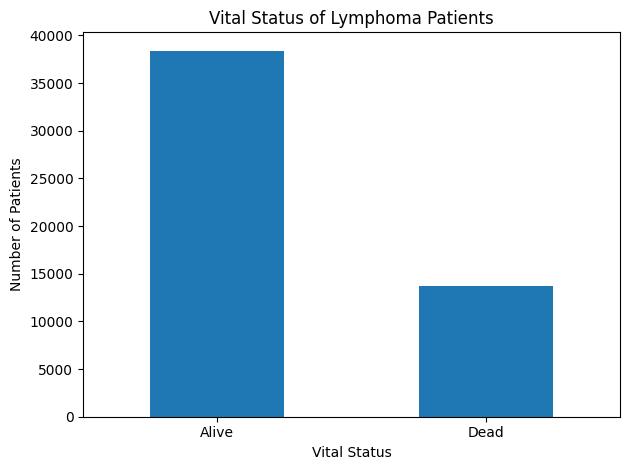

In [1307]:
df["vital_status"].value_counts().plot(kind="bar")

plt.title("Vital Status of Lymphoma Patients")
plt.xlabel("Vital Status")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

In [1308]:
import plotly.express as px

# 1. Bar Chart لـ Vital Status
fig_vital = px.histogram(
    df_clean, 
    x='vital_status', 
    color='vital_status',
    title='<b>Patient Count by Vital Status</b>',
    labels={'vital_status': 'Vital Status'},
    color_discrete_map={'Alive': '#2ca02c', 'Dead': '#d62728'},
    text_auto=True
)
fig_vital.update_layout(template='plotly_white', showlegend=False, height=450)
fig_vital.show()

# 2. Bar Chart لـ Sex
fig_sex = px.histogram(
    df_clean, 
    x='Sex', 
    color='Sex',
    title='<b>Patient Count by Sex</b>',
    labels={'Sex': 'Gender'},
    color_discrete_sequence=['#9b59b6', '#3498db'],
    text_auto=True
)
fig_sex.update_layout(template='plotly_white', showlegend=False, height=450)
fig_sex.show()

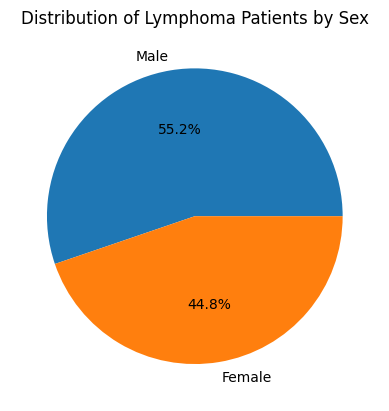

In [1309]:
df["Sex"].value_counts().plot(kind="pie", autopct="%1.1f%%")
plt.title("Distribution of Lymphoma Patients by Sex")
plt.ylabel("")
plt.show()

In [1310]:
import plotly.express as px

fig_stage = px.histogram(
    df_clean, 
    x='ajcc_combined', 
    color='ajcc_combined',
    title='<b>Patient Count by Cancer Stage (ajcc_combined)</b>',
    text_auto=True,
    category_orders={'ajcc_combined': sorted(df_clean['ajcc_combined'].dropna().unique())}
)
fig_stage.update_layout(template='plotly_white', showlegend=False, height=450)
fig_stage.show()

fig_treatment = px.histogram(
    df_clean, 
    x='chemo', 
    color='Radiation recode',
    barmode='group',
    title='<b>Distribution of Chemotherapy and Radiation Treatment</b>',
    text_auto=True
)
fig_treatment.update_layout(template='plotly_white', height=450)
fig_treatment.show()

In [1311]:

def simplify_stage(stage):
    if pd.isna(stage):
        return 'Unknown'
    stage_str = str(stage).upper()
    if 'IV' in stage_str or '4' in stage_str:
        return 'Stage IV'
    elif 'III' in stage_str or '3' in stage_str:
        return 'Stage III'
    elif 'II' in stage_str or '2' in stage_str:
        return 'Stage II'
    elif 'I' in stage_str or '1' in stage_str:
        return 'Stage I'
    return 'Other'

df_clean['stage_grouped'] = df_clean['ajcc_combined'].apply(simplify_stage)

stage_counts = df_clean['stage_grouped'].value_counts().reindex(['Stage I', 'Stage II', 'Stage III', 'Stage IV', 'Other', 'Unknown']).dropna().reset_index()
stage_counts.columns = ['Stage', 'Patient Count']

fig_stage_clean = px.bar(
    stage_counts, 
    x='Stage', 
    y='Patient Count',
    text='Patient Count',
    title='<b>Patient Count by Main Cancer Stage (Grouped)</b>',
    color='Stage',
    color_discrete_sequence=['#2ecc71', '#3498db', '#f1c40f', '#e74c3c', '#95a5a6']
)

fig_stage_clean.update_traces(textposition='outside')
fig_stage_clean.update_layout(
    template='plotly_white',
    showlegend=False,
    xaxis_title='<b>Cancer Stage</b>',
    yaxis_title='<b>Patient Count</b>',
    title_font_size=18,
    height=450
)

fig_stage_clean.show()



> **Clinical Insight (Cancer Stage Distribution):**
> "By consolidating detailed staging sub-categories into major cancer stages (I–IV), the distribution reveals that the majority of patients are diagnosed in mid-to-advanced stages (Stage II and Stage IV). This highlights a critical clinical pattern where late-stage detection significantly impacts overall survival outcomes."

In [1312]:
import plotly.express as px

def simplify_radiation(rad):
    if pd.isna(rad) or 'None' in str(rad) or 'Unknown' in str(rad):
        return 'None / Unknown'
    elif 'Beam' in str(rad):
        return 'Beam Radiation'
    else:
        return 'Other Radiation Methods'

df_clean['radiation_grouped'] = df_clean['Radiation recode'].apply(simplify_radiation)

fig_treatment_clean = px.histogram(
    df_clean, 
    x='chemo', 
    color='radiation_grouped',
    barmode='group',
    text_auto=True,
    title='<b>Distribution of Chemotherapy vs. Radiation Treatment</b>',
    labels={'chemo': 'Chemotherapy Received', 'radiation_grouped': 'Radiation Treatment'},
    color_discrete_map={
        'None / Unknown': '#e74c3c', 
        'Beam Radiation': '#3498db', 
        'Other Radiation Methods': '#9b59b6'
    }
)

fig_treatment_clean.update_layout(
    template='plotly_white',
    xaxis_title='<b>Chemotherapy Status</b>',
    yaxis_title='<b>Patient Count</b>',
    title_font_size=18,
    height=480,
    legend=dict(title='Radiation Category', orientation="h", yanchor="bottom", y=1.02, xanchor="right", x=1)
)

fig_treatment_clean.show()



> **Clinical Insight (Treatment Modality Combinations):**
> "The distribution reveals that chemotherapy is the primary treatment modality administered to the majority of patients (~40k cases), whereas radiation therapy is utilized less frequently. Among patients receiving chemotherapy, approximately 27.5k did not receive radiation ('None/Unknown'), while ~11.8k received combined systemic therapy (Chemotherapy + External Beam Radiation). Combined multi-modal treatment represents a distinct high-risk or advanced-stage patient subgroup."

In [1313]:
import plotly.express as px

other_radiation_df = df_clean[
    ~df_clean['Radiation recode'].astype(str).str.contains('None|Unknown|Beam', case=False, na=True)
]

other_counts = other_radiation_df['Radiation recode'].value_counts().reset_index()
other_counts.columns = ['Radiation Method', 'Patient Count']

fig_other = px.bar(
    other_counts,
    y='Radiation Method',
    x='Patient Count',
    text='Patient Count',
    orientation='h',
    title='<b>Detailed Breakdown of Other/Minor Radiation Methods</b>',
    color='Patient Count',
    color_continuous_scale='Purples'
)

fig_other.update_traces(textposition='outside')
fig_other.update_layout(
    template='plotly_white',
    yaxis_title='<b>Radiation Method</b>',
    xaxis_title='<b>Patient Count</b>',
    title_font_size=16,
    height=450,
    showlegend=False
)

fig_other.show()



> **Minor Treatment Modalities Insight:**
> "A specialized breakdown of non-standard radiation therapies shows that 'Recommended, unknown if administered' and 'Radioactive implants (brachytherapy)' represent the most frequent minor radiation protocols, whereas options like radioisotopes or combination methods remain extremely rare exceptions in this patient cohort."

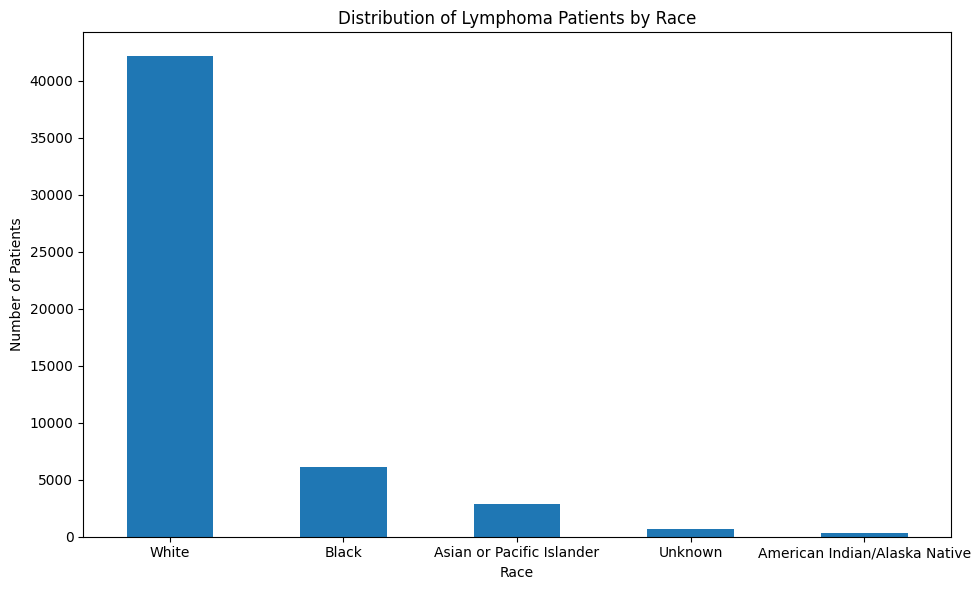

In [1314]:
plt.figure(figsize=(10, 6))

df["race"].value_counts().plot(kind="bar")

plt.title("Distribution of Lymphoma Patients by Race")
plt.xlabel("Race")
plt.ylabel("Number of Patients")

plt.xticks(rotation=0)
plt.tight_layout()

plt.show()

In [1315]:

fig_race = px.histogram(
    df_clean, 
    x='race', 
    color='race',
    title='<b>Patient Distribution by Race</b>',
    text_auto=True
)
fig_race.update_layout(template='plotly_white', showlegend=False, height=400)
fig_race.show()





> **Demographic Insight (Patient Race Distribution):**
> "The racial distribution of the patient cohort exhibits a pronounced imbalance, with the vast majority of cases categorized as White (~40.1k patients, representing over 80% of the dataset). Black patients constitute the second largest group (~6.0k), followed by Asian or Pacific Islander (~2.8k) and American Indian/Alaska Native (~289). This demographic concentration should be taken into consideration when evaluating model generalizability across diverse racial subpopulations."

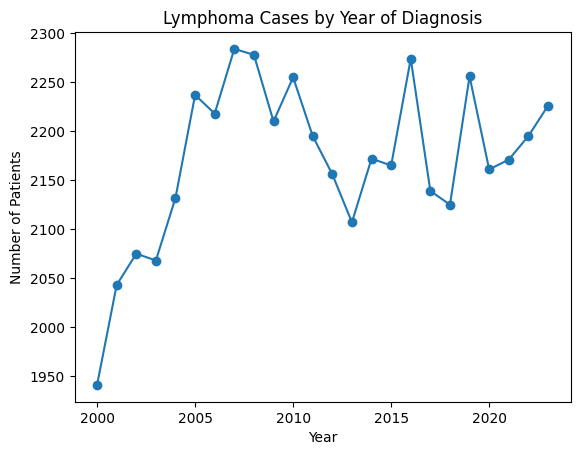

In [1316]:
df["Year of diagnosis"].value_counts().sort_index().plot(kind="line", marker="o")
plt.title("Lymphoma Cases by Year of Diagnosis")
plt.xlabel("Year")
plt.ylabel("Number of Patients")
plt.show()

In [1317]:
import plotly.express as px

yearly_counts = df_clean['Year of diagnosis'].value_counts().reset_index()
yearly_counts.columns = ['Year of diagnosis', 'Patient Count']
yearly_counts = yearly_counts.sort_values('Year of diagnosis')

fig_years = px.line(
    yearly_counts, 
    x='Year of diagnosis', 
    y='Patient Count',
    title='<b>Diagnosis Trend Over Years</b>',
    markers=True, 
    color_discrete_sequence=['#2b5c8f']
)

fig_years.update_layout(
    template='plotly_white',
    xaxis_title='<b>Year of Diagnosis</b>',
    yaxis_title='<b>Patient Count</b>',
    title_font_size=18,
    height=400
)

fig_years.update_yaxes(rangemode="tozero")

fig_years.show()



> **Temporal Trend Insight (Diagnosis Trend Over Years):**
> "The line plot underscores a highly stable longitudinal trend in annual cancer diagnoses from 2000 to 2022, consistently hovering around ~2,000 cases per year. The absence of volatile fluctuations or abrupt spikes confirms consistent sampling methodology and data reporting standards across the entire temporal window."

In [1318]:
import plotly.express as px

# 1. تجميع أعلى 10 أكواد وتحويل العمود لـ string لمنع تعامله كأرقام متصلة
top_sites = df_clean['primary_site_code'].value_counts().head(10).reset_index()
top_sites.columns = ['primary_site_code', 'count']
top_sites['primary_site_code'] = top_sites['primary_site_code'].astype(str)

# 2. رسم Bar Chart أفقي نظيف
fig_sites = px.bar(
    top_sites, 
    y='primary_site_code', 
    x='count',
    text='count',
    orientation='h',
    title='<b>Top 10 Primary Site Codes Distribution</b>',
    color='count',
    color_continuous_scale='Blues'
)

fig_sites.update_traces(textposition='outside')
fig_sites.update_layout(
    template='plotly_white',
    yaxis={'categoryorder': 'total ascending'},
    yaxis_title='<b>Primary Site Code</b>',
    xaxis_title='<b>Patient Count</b>',
    title_font_size=18,
    height=450,
    showlegend=False
)

fig_sites.show()

In [1319]:

site_map = {
    '778': 'Lymph Nodes (C77.8)',
    '770': 'Respiratory / Lung (C77.0)',
    '779': 'Lymph Nodes, NOS (C77.9)',
    '771': 'Intra-abdominal Lymph (C77.1)',
    '773': 'Axillary / Arm Lymph (C77.3)',
    '774': 'Inguinal / Leg Lymph (C77.4)',
    '772': 'Pelvic Lymph Nodes (C77.2)',
    '775': 'Retroperitoneal Lymph (C77.5)',
    '341': 'Bronchus & Lung (C34.1)',
    '381': 'Trachea / Mediastinum (C38.1)'
}


top_sites = df_clean['primary_site_code'].astype(str).value_counts().head(10).reset_index()
top_sites.columns = ['primary_site_code', 'count']


top_sites['site_label'] = top_sites['primary_site_code'].map(site_map).fillna(top_sites['primary_site_code'])


fig_sites = px.bar(
    top_sites, 
    y='site_label', 
    x='count',
    text='count',
    orientation='h',
    title='<b>Top 10 Primary Tumor Sites Distribution</b>',
    color='count',
    color_continuous_scale='Blues'
)

fig_sites.update_traces(textposition='outside')
fig_sites.update_layout(
    template='plotly_white',
    yaxis={'categoryorder': 'total ascending'},
    yaxis_title='<b>Primary Tumor Site</b>',
    xaxis_title='<b>Patient Count</b>',
    title_font_size=18,
    height=480,
    showlegend=False
)

fig_sites.show()



> **Clinical Site Distribution Insight:**
> "Analysis of primary tumor sites reveals a strong concentration in lymph node involvement (led by C77.8 and C77.0 regional lymph node sites, accounting for over 26,000 cases). This indicates that a significant portion of the patient cohort was diagnosed at stages involving regional lymphatic spread."

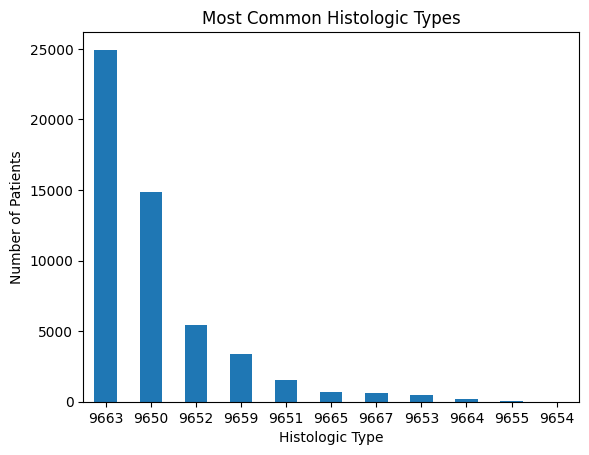

In [1320]:
df["Histologic Type ICD-O-3"].value_counts().head(11).plot(kind="bar")
plt.title("Most Common Histologic Types")
plt.xlabel("Histologic Type")
plt.ylabel("Number of Patients")
plt.xticks(rotation=0)
plt.show()

In [1321]:
top_histo = df_clean['Histologic Type ICD-O-3'].value_counts().head(10).reset_index()
top_histo.columns = ['Histologic Type ICD-O-3', 'count']

fig_histo = px.bar(
    top_histo, 
    x='Histologic Type ICD-O-3', 
    y='count',
    text='count',
    title='<b>Top 10 Histologic Types (ICD-O-3)</b>',
    color='count',
    color_continuous_scale='Oranges'
)
fig_histo.update_layout(template='plotly_white', height=450)
fig_histo.show()

In [1322]:
import plotly.express as px

histo_map = {
    '9663': 'Nodular Sclerosis Hodgkin Lymphoma (9663)',
    '9650': 'Hodgkin Lymphoma, NOS (9650)',
    '9652': 'Mixed Cellularity Hodgkin Lymphoma (9652)',
    '9651': 'Lymphocyte-rich Hodgkin Lymphoma (9651)',
    '9665': 'Nodular Sclerosis, Grade 1 (9665)',
    '9667': 'Nodular Sclerosis, Grade 2 (9667)',
    '9653': 'Lymphocyte Depletion Hodgkin Lymphoma (9653)',
    '9664': 'Nodular Sclerosis, Phase Unspecified (9664)',
    '9659': 'Hodgkin Lymphoma, Nodular (9659)',
    '9654': 'Lymphocyte Depletion, Diffuse Fibrosis (9654)'
}

# 2. تجميع أعلى 10 أنواع وتجهيز البيانات
top_histo = df_clean['Histologic Type ICD-O-3'].astype(str).value_counts().head(10).reset_index()
top_histo.columns = ['Histologic_Code', 'count']

# استبدال الكود بالاسم الطبي الواضح
top_histo['Histologic_Label'] = top_histo['Histologic_Code'].map(histo_map).fillna(top_histo['Histologic_Code'])

# 3. رسم Bar Chart أفقي مرتب ومنسق
fig_histo = px.bar(
    top_histo, 
    y='Histologic_Label', 
    x='count',
    text='count',
    orientation='h',
    title='<b>Top 10 Histologic Types Distribution</b>',
    color='count',
    color_continuous_scale='Oranges'
)

fig_histo.update_traces(textposition='outside')
fig_histo.update_layout(
    template='plotly_white',
    yaxis={'categoryorder': 'total ascending'},
    yaxis_title='<b>Histologic Type</b>',
    xaxis_title='<b>Patient Count</b>',
    title_font_size=18,
    height=480,
    showlegend=False
)

fig_histo.show()



> **Histologic Subtype Insight:**
> "The histological classification shows a dominant prevalence of Nodular Sclerosis Hodgkin Lymphoma (Code 9663, with over 23,000 cases), followed by Hodgkin Lymphoma NOS (Code 9650, ~14,000 cases) and Mixed Cellularity (Code 9652, ~5,300 cases). These three subtypes constitute the vast majority of diagnosed cases in the dataset."

In [1323]:
import plotly.express as px

# 1. تجميع بيانات العلاج الكيماوي
chemo_counts = df_clean['chemo'].value_counts().reset_index()
chemo_counts.columns = ['Chemotherapy Status', 'Count']

# 2. رسم Pie Chart أنيق بـ Plotly
fig_chemo = px.pie(
    chemo_counts, 
    names='Chemotherapy Status', 
    values='Count',
    title='<b>Chemotherapy Administration Distribution</b>',
    color_discrete_sequence=['#2b5c8f', '#d95f02']
)

fig_chemo.update_traces(textposition='inside', textinfo='percent+label')
fig_chemo.update_layout(
    template='plotly_white',
    title_font_size=18,
    height=400,
    showlegend=True
)

fig_chemo.show()



> **Treatment Distribution Insight (Chemotherapy):**
> "The vast majority of patients in the cohort received chemotherapy as part of their primary treatment plan, representing 81.8% of cases. Meanwhile, 18.2% of patients had no documented chemotherapy or an unknown administration status. This strong imbalance highlights chemotherapy as a core standard of care within this patient population."

# Data Preprocessing & Encoding:

In [1324]:
df_clean.head(5)

,age_group,Year of diagnosis,Sex,race,primary_site_code,Histologic Type ICD-O-3,Radiation recode,chemo,Survival months flag,Survival months,vital_status,cause_specific_death,other_cause_death,Year of follow-up recode,ajcc_combined,stage_grouped,radiation_grouped
0,65-69 years,2016,Female,White,774,9659,Beam radiation,No/Unknown,Complete dates are available and there are mor...,88.0,Alive,Alive or dead of other cause,Alive or dead due to cancer,2023,Stage I,Stage I,Beam Radiation
1,65-69 years,2018,Female,White,779,9659,None/Unknown,Yes,Complete dates are available and there are mor...,65.0,Alive,Alive or dead of other cause,Alive or dead due to cancer,2023,Stage IV,Stage IV,None / Unknown
2,30-34 years,2000,Female,Black,774,9659,Beam radiation,No/Unknown,Complete dates are available and there are mor...,284.0,Alive,Alive or dead of other cause,Alive or dead due to cancer,2023,Stage II,Stage II,Beam Radiation
3,90+ years,2015,Female,White,778,9663,None/Unknown,Yes,Complete dates are available and there are mor...,28.0,Dead,Dead (attributable to this cancer dx),Alive or dead due to cancer,2017,IVA,Stage IV,None / Unknown
4,60-64 years,2009,Male,White,778,9652,None/Unknown,Yes,Complete dates are available and there are mor...,8.0,Dead,Dead (attributable to this cancer dx),Alive or dead due to cancer,2009,IIIB,Stage III,None / Unknown


In [1325]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49280 entries, 0 to 52080
Data columns (total 17 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age_group                 49280 non-null  object 
 1   Year of diagnosis         49280 non-null  int64  
 2   Sex                       49280 non-null  object 
 3   race                      49280 non-null  object 
 4   primary_site_code         49280 non-null  int64  
 5   Histologic Type ICD-O-3   49280 non-null  int64  
 6   Radiation recode          49280 non-null  object 
 7   chemo                     49280 non-null  object 
 8   Survival months flag      49280 non-null  object 
 9   Survival months           49280 non-null  float64
 10  vital_status              49280 non-null  object 
 11  cause_specific_death      49280 non-null  object 
 12  other_cause_death         49280 non-null  object 
 13  Year of follow-up recode  49280 non-null  int64  
 14  ajcc_combin

In [1326]:
# Check the distribution of patient status (Alive vs Dead)
print("Vital Status:")
print(df_clean['vital_status'].value_counts())

# Check how many patients died specifically from cancer vs other/unknown causes
print("\nCause Specific Death:")
print(df_clean['cause_specific_death'].value_counts())

# Check the mirrored column: deaths attributable to causes other than cancer
print("\nOther Cause Death:")
print(df_clean['other_cause_death'].value_counts())

# Preview the first few survival month values to check data type and format
print("\nSurvival Months:")
print(df_clean['Survival months'].head())

Vital Status:
vital_status
Alive    35896
Dead     13384
Name: count, dtype: int64

Cause Specific Death:
cause_specific_death
Alive or dead of other cause             41639
Dead (attributable to this cancer dx)     7391
Dead (missing/unknown COD)                 250
Name: count, dtype: int64

Other Cause Death:
other_cause_death
Alive or dead due to cancer                                43287
Dead (attributable to causes other than this cancer dx)     5743
Dead (missing/unknown COD)                                   250
Name: count, dtype: int64

Survival Months:
0     88.0
1     65.0
2    284.0
3     28.0
4      8.0
Name: Survival months, dtype: float64


In [1327]:
import numpy as np

# Build the Risk Level target column based on cause of death and survival duration
# (this column is what the model will later learn to predict)
df_clean['risk_level'] = np.select(
    [
        # Patient died specifically because of Hodgkin Lymphoma -> strongest evidence of risk
        df_clean['cause_specific_death'] == 'Dead (attributable to this cancer dx)',

        # Cause of death is unknown -> treated as Medium (uncertain case)
        df_clean['cause_specific_death'] == 'Dead (missing/unknown COD)',

        # Alive or died of another cause, AND survived 60+ months -> strong evidence of low risk
        (df_clean['cause_specific_death'] == 'Alive or dead of other cause') &
        (df_clean['Survival months'] >= 60),

        # Alive or died of another cause, but survived less than 60 months -> not enough
        # evidence to confirm low risk, so treated as Medium
        (df_clean['cause_specific_death'] == 'Alive or dead of other cause') &
        (df_clean['Survival months'] < 60)
    ],
    [
        'High',
        'Medium',
        'Low',
        'Medium'
    ],
    default='Unknown'  # safety net for any case not covered by the conditions above
)

print(df_clean['risk_level'].value_counts())

risk_level
Low       29487
Medium    12402
High       7391
Name: count, dtype: int64


In [1328]:
# Sanity check: verify that each Risk_Level category was derived from the
# correct cause_specific_death values, with no unexpected mismatches
pd.crosstab(
    df_clean['risk_level'],
    df_clean['cause_specific_death']
)

cause_specific_death,Alive or dead of other cause,Dead (attributable to this cancer dx),Dead (missing/unknown COD)
risk_level,,,
High,0,7391,0
Low,29487,0,0
Medium,12152,0,250


In [1329]:
# Remove target-related columns that were used to build Risk_Level —
# keeping them in the features would leak the answer directly into the model (Data Leakage)
leakage_cols = [
    'vital_status',
    'cause_specific_death',
    'other_cause_death',
    'Survival months',
    'Survival months flag',
    'Year of follow-up recode'
]

df_model = df_clean.drop(columns=leakage_cols)

print(df_model.shape)
print(df_model.columns.tolist())

(49280, 12)
['age_group', 'Year of diagnosis', 'Sex', 'race', 'primary_site_code', 'Histologic Type ICD-O-3', 'Radiation recode', 'chemo', 'ajcc_combined', 'stage_grouped', 'radiation_grouped', 'risk_level']


In [1330]:

cols_for_drop = ['stage_grouped', 'radiation_grouped']

df_model.drop(columns=[i for i in cols_for_drop if i in df_model.columns], inplace=True, errors='ignore')

print(df_model.shape)
print(df_model.columns.tolist())

(49280, 10)
['age_group', 'Year of diagnosis', 'Sex', 'race', 'primary_site_code', 'Histologic Type ICD-O-3', 'Radiation recode', 'chemo', 'ajcc_combined', 'risk_level']


In [1331]:
# Preview remaining unencoded columns before converting them to numeric
# (checking exact values and their counts to avoid missing any category)

print("AJCC:")
print(df_model['ajcc_combined'].value_counts())

print("\nRadiation:")
print(df_model['Radiation recode'].value_counts())

print("\nChemo:")
print(df_model['chemo'].value_counts())

print("\nSex:")
print(df_model['Sex'].value_counts())

AJCC:
ajcc_combined
Stage IV    9677
IIA         7117
Stage II    6929
IA          3676
IVB         3356
IIB         3237
Stage I     3028
IIIB        1906
IIIA        1764
IVA         1622
I           1049
II           914
IB           896
IIISB        743
IV           589
IIISA        487
IIEA         484
III          375
IIEB         370
IIIEB        140
IEA          125
IIE          119
IIIESB       108
IIIEA        106
IIIS         100
IISB          68
IIIESA        65
IEB           47
IE            42
IISA          37
IIIE          28
IIS           18
IIIES         15
IIESB         13
IIESA         12
ISB            9
ISA            7
IIES           2
Name: count, dtype: int64

Radiation:
Radiation recode
None/Unknown                                             34530
Beam radiation                                           13603
Recommended, unknown if administered                       693
Refused (1988+)                                            263
Radiation, NOS  method or s

In [1332]:
# Convert Sex to binary numeric values (Female=0, Male=1)
df_model['Sex'] = df_model['Sex'].map({
    'Female': 0,
    'Male': 1
})

print(df_model['Sex'].value_counts())

Sex
1    27358
0    21922
Name: count, dtype: int64


In [1333]:
# Convert chemo to binary numeric values (No/Unknown=0, Yes=1)
df_model['chemo'] = df_model['chemo'].map({
    'No/Unknown': 0,
    'Yes': 1
})

print(df_model['chemo'].value_counts())

chemo
1    40295
0     8985
Name: count, dtype: int64


In [1334]:
# Check all unique age categories before applying ordinal encoding
print(df_model['age_group'].unique())

['65-69 years' '30-34 years' '90+ years' '60-64 years' '05-09 years'
 '75-79 years' '45-49 years' '15-19 years' '85-89 years' '55-59 years'
 '70-74 years' '40-44 years' '80-84 years' '50-54 years' '20-24 years'
 '10-14 years' '25-29 years' '35-39 years' '01-04 years']


In [1335]:
# Define the natural order of age groups from youngest to oldest
# ⚠️ Make sure '00 years' is included here if it exists in the data
age_order = [
    '01-04 years',
    '05-09 years',
    '10-14 years',
    '15-19 years',
    '20-24 years',
    '25-29 years',
    '30-34 years',
    '35-39 years',
    '40-44 years',
    '45-49 years',
    '50-54 years',
    '55-59 years',
    '60-64 years',
    '65-69 years',
    '70-74 years',
    '75-79 years',
    '80-84 years',
    '85-89 years',
    '90+ years'
]

# Build a mapping from each age category to its ordinal rank (position in the list)
age_mapping = {age: i for i, age in enumerate(age_order)}

# Apply the ordinal encoding
df_model['age_group'] = df_model['age_group'].map(age_mapping)

print(df_model['age_group'].value_counts().sort_index())

age_group
0       99
1      533
2     1535
3     3854
4     5337
5     5144
6     4637
7     3770
8     3547
9     3110
10    2947
11    2782
12    2634
13    2595
14    2307
15    2001
16    1416
17     799
18     233
Name: count, dtype: int64


In [1336]:
# Check the distribution of race categories before one-hot encoding
print(df_model['race'].value_counts())

race
White                            40103
Black                             6024
Asian or Pacific Islander         2864
American Indian/Alaska Native      289
Name: count, dtype: int64


In [1337]:
# Apply One-Hot Encoding to race with drop_first=True to avoid dummy variable trap
df_model = pd.get_dummies(
    df_model,
    columns=['race'],
    prefix='race',
    drop_first=True,  
    dtype=int
)

print(df_model.shape)
df_model.head()

(49280, 12)


,age_group,Year of diagnosis,Sex,primary_site_code,Histologic Type ICD-O-3,Radiation recode,chemo,ajcc_combined,risk_level,race_Asian or Pacific Islander,race_Black,race_White
0,13,2016,0,774,9659,Beam radiation,0,Stage I,Low,0,0,1
1,13,2018,0,779,9659,None/Unknown,1,Stage IV,Low,0,0,1
2,6,2000,0,774,9659,Beam radiation,0,Stage II,Low,0,1,0
3,18,2015,0,778,9663,None/Unknown,1,IVA,High,0,0,1
4,12,2009,1,778,9652,None/Unknown,1,IIIB,High,0,0,1


In [1338]:
# Review all current column names after encoding Sex, chemo, age_group, and race
print(df_model.columns.tolist())

['age_group', 'Year of diagnosis', 'Sex', 'primary_site_code', 'Histologic Type ICD-O-3', 'Radiation recode', 'chemo', 'ajcc_combined', 'risk_level', 'race_Asian or Pacific Islander', 'race_Black', 'race_White']


In [1339]:
# Quickly list only the columns that are still text (object dtype) —
# these are the ones still needing encoding before the data is ready for a model
print(df_model.select_dtypes(include='object').columns.tolist())

['Radiation recode', 'ajcc_combined', 'risk_level']


In [1340]:
# Check the distribution of radiation treatment categories before one-hot encoding
print(df_model['Radiation recode'].value_counts())

Radiation recode
None/Unknown                                             34530
Beam radiation                                           13603
Recommended, unknown if administered                       693
Refused (1988+)                                            263
Radiation, NOS  method or source not specified             160
Combination of beam with implants or isotopes               14
Radioactive implants (includes brachytherapy) (1988+)        9
Radioisotopes (1988+)                                        8
Name: count, dtype: int64


In [1341]:
# Apply One-Hot Encoding to Radiation recode
# (creates a separate 0/1 column for each of the 8 radiation categories)
df_model = pd.get_dummies(
    df_model,
    columns=['Radiation recode'],
    prefix='radiation',
    drop_first=True,
    dtype=int
)

In [1342]:
print(df_model.columns.tolist())

['age_group', 'Year of diagnosis', 'Sex', 'primary_site_code', 'Histologic Type ICD-O-3', 'chemo', 'ajcc_combined', 'risk_level', 'race_Asian or Pacific Islander', 'race_Black', 'race_White', 'radiation_Combination of beam with implants or isotopes', 'radiation_None/Unknown', 'radiation_Radiation, NOS  method or source not specified', 'radiation_Radioactive implants (includes brachytherapy) (1988+)', 'radiation_Radioisotopes (1988+)', 'radiation_Recommended, unknown if administered', 'radiation_Refused (1988+)']


In [1343]:
print(df_model['ajcc_combined'].value_counts())

ajcc_combined
Stage IV    9677
IIA         7117
Stage II    6929
IA          3676
IVB         3356
IIB         3237
Stage I     3028
IIIB        1906
IIIA        1764
IVA         1622
I           1049
II           914
IB           896
IIISB        743
IV           589
IIISA        487
IIEA         484
III          375
IIEB         370
IIIEB        140
IEA          125
IIE          119
IIIESB       108
IIIEA        106
IIIS         100
IISB          68
IIIESA        65
IEB           47
IE            42
IISA          37
IIIE          28
IIS           18
IIIES         15
IIESB         13
IIESA         12
ISB            9
ISA            7
IIES           2
Name: count, dtype: int64


In [1344]:
print(df_model['ajcc_combined'].unique())

['Stage I' 'Stage IV' 'Stage II' 'IVA' 'IIIB' 'IIA' 'IVB' 'IA' 'IIB' 'II'
 'IIIA' 'I' 'III' 'IEA' 'IIE' 'IIEA' 'IB' 'IIISB' 'IIEB' 'IISB' 'IIIEB'
 'IV' 'ISB' 'IEB' 'IIISA' 'IIIEA' 'IIIESB' 'IIESA' 'IISA' 'IIIESA' 'IIS'
 'IIIE' 'IIIS' 'IIIES' 'IE' 'IIESB' 'ISA' 'IIES']


In [1345]:
# Test: confirm the regex correctly extracts the stage number
# even from the "Stage X" format (not just "XB"/"XA" style)
test_values = ['Stage I', 'Stage IV', 'Stage II', 'IVA', 'IIIB', 'IIA', 'IVB', 'IA', 'II', 'I']
test_series = pd.Series(test_values)
print(test_series.str.extract(r'(IV|III|II|I)'))

     0
0    I
1   IV
2   II
3   IV
4  III
5   II
6   IV
7    I
8   II
9    I


In [1346]:
# Extract the numeric stage (I, II, III, IV) from ajcc_combined,
# handling both "Stage X" and "XA"/"XB" formats correctly
df_model['ajcc_stage'] = df_model['ajcc_combined'].str.extract(r'(IV|III|II|I)')

stage_mapping = {'I': 1, 'II': 2, 'III': 3, 'IV': 4}
df_model['ajcc_stage_encoded'] = df_model['ajcc_stage'].map(stage_mapping)

# Extract whether B symptoms are present (value ends with 'B')
df_model['has_B_symptom'] = df_model['ajcc_combined'].str.endswith('B').astype(int)

print(df_model[['ajcc_combined', 'ajcc_stage_encoded', 'has_B_symptom']].sample(10))
print("\nMissing in ajcc_stage_encoded:", df_model['ajcc_stage_encoded'].isnull().sum())

      ajcc_combined  ajcc_stage_encoded  has_B_symptom
13145           IIB                   2              1
8993       Stage IV                   4              0
10349           IIE                   2              0
2568       Stage IV                   4              0
43170          IIIA                   3              0
43710          IIEB                   2              1
17034           IVA                   4              0
11548      Stage IV                   4              0
11629          IIIA                   3              0
40171           IIB                   2              1

Missing in ajcc_stage_encoded: 0


In [1347]:
print(df_model['ajcc_stage'].value_counts())

ajcc_stage
II     19320
IV     15244
I       8879
III     5837
Name: count, dtype: int64


In [1348]:
# Convert the Roman numeral stage (I-IV) into an ordinal numeric value,
# preserving the natural severity order (Stage IV is the most advanced)
stage_mapping = {
    'I': 1,
    'II': 2,
    'III': 3,
    'IV': 4
}

df_model['ajcc_stage_encoded'] = df_model['ajcc_stage'].map(stage_mapping)

print(df_model['ajcc_stage_encoded'].value_counts().sort_index())

ajcc_stage_encoded
1     8879
2    19320
3     5837
4    15244
Name: count, dtype: int64


In [1349]:
# Sanity check: visually confirm that each Roman numeral stage
# maps correctly to its corresponding numeric value
print(df_model[['ajcc_stage', 'ajcc_stage_encoded']].head(10))

  ajcc_stage  ajcc_stage_encoded
0          I                   1
1         IV                   4
2         II                   2
3         IV                   4
4        III                   3
5         II                   2
6         IV                   4
7        III                   3
8         IV                   4
9         II                   2


In [1350]:
# Extract whether B symptoms are present — AJCC stages ending in 'B'
# indicate systemic symptoms (fever, night sweats, weight loss)
df_model['has_B_symptom'] = df_model['ajcc_combined'].str.endswith('B').astype(int)

print(df_model['has_B_symptom'].value_counts())
print(df_model[['ajcc_combined', 'has_B_symptom']].sample(10))

has_B_symptom
0    38387
1    10893
Name: count, dtype: int64
      ajcc_combined  has_B_symptom
29033           IVA              0
7718            IIB              1
11912      Stage II              0
24493      Stage IV              0
6317            IIA              0
36864          IIIA              0
40076           IIA              0
21201            IA              0
11769          IIIB              1
40156             I              0


In [1351]:
print(df_model['risk_level'].value_counts())

risk_level
Low       29487
Medium    12402
High       7391
Name: count, dtype: int64


In [1352]:
print(df_model['age_group'].value_counts())

age_group
4     5337
5     5144
6     4637
3     3854
7     3770
8     3547
9     3110
10    2947
11    2782
12    2634
13    2595
14    2307
15    2001
2     1535
16    1416
17     799
1      533
18     233
0       99
Name: count, dtype: int64


In [1353]:
print(df_model['Sex'].value_counts())

Sex
1    27358
0    21922
Name: count, dtype: int64


In [1354]:
print(df_model['chemo'].value_counts())

chemo
1    40295
0     8985
Name: count, dtype: int64


In [1355]:
# Check the distribution of histologic subtypes before one-hot encoding
print(df_model['Histologic Type ICD-O-3'].value_counts())

Histologic Type ICD-O-3
9663    23123
9650    14023
9652     5335
9659     3287
9651     1500
9665      710
9667      602
9653      444
9664      217
9655       27
9654        9
9661        2
9662        1
Name: count, dtype: int64


In [1356]:
print(df_model['primary_site_code'].value_counts())

primary_site_code
778    26055
770     8115
779     6292
771     3075
773     2025
       ...  
710        1
716        1
159        1
189        1
40         1
Name: count, Length: 136, dtype: int64


In [1357]:
print(df_model.select_dtypes(include=['object', 'string']).columns.tolist())

['ajcc_combined', 'risk_level', 'ajcc_stage']


In [1358]:
df_model = df_model.drop(columns=['ajcc_combined', 'ajcc_stage'])

print(df_model.columns.tolist())

['age_group', 'Year of diagnosis', 'Sex', 'primary_site_code', 'Histologic Type ICD-O-3', 'chemo', 'risk_level', 'race_Asian or Pacific Islander', 'race_Black', 'race_White', 'radiation_Combination of beam with implants or isotopes', 'radiation_None/Unknown', 'radiation_Radiation, NOS  method or source not specified', 'radiation_Radioactive implants (includes brachytherapy) (1988+)', 'radiation_Radioisotopes (1988+)', 'radiation_Recommended, unknown if administered', 'radiation_Refused (1988+)', 'ajcc_stage_encoded', 'has_B_symptom']


In [1359]:
print(df_model.isnull().sum())

age_group                                                          0
Year of diagnosis                                                  0
Sex                                                                0
primary_site_code                                                  0
Histologic Type ICD-O-3                                            0
chemo                                                              0
risk_level                                                         0
race_Asian or Pacific Islander                                     0
race_Black                                                         0
race_White                                                         0
radiation_Combination of beam with implants or isotopes            0
radiation_None/Unknown                                             0
radiation_Radiation, NOS  method or source not specified           0
radiation_Radioactive implants (includes brachytherapy) (1988+)    0
radiation_Radioisotopes (1988+)   

In [1360]:
print(df_model.dtypes)

age_group                                                           int64
Year of diagnosis                                                   int64
Sex                                                                 int64
primary_site_code                                                   int64
Histologic Type ICD-O-3                                             int64
chemo                                                               int64
risk_level                                                         object
race_Asian or Pacific Islander                                      int64
race_Black                                                          int64
race_White                                                          int64
radiation_Combination of beam with implants or isotopes             int64
radiation_None/Unknown                                              int64
radiation_Radiation, NOS  method or source not specified            int64
radiation_Radioactive implants (includ

In [1361]:
print("Shape:", df_model.shape)
print("\nColumns:", df_model.columns.tolist())

Shape: (49280, 19)

Columns: ['age_group', 'Year of diagnosis', 'Sex', 'primary_site_code', 'Histologic Type ICD-O-3', 'chemo', 'risk_level', 'race_Asian or Pacific Islander', 'race_Black', 'race_White', 'radiation_Combination of beam with implants or isotopes', 'radiation_None/Unknown', 'radiation_Radiation, NOS  method or source not specified', 'radiation_Radioactive implants (includes brachytherapy) (1988+)', 'radiation_Radioisotopes (1988+)', 'radiation_Recommended, unknown if administered', 'radiation_Refused (1988+)', 'ajcc_stage_encoded', 'has_B_symptom']


In [1362]:
print("Primary Site unique values:", df_model['primary_site_code'].nunique())
print("Histologic Type unique values:", df_model['Histologic Type ICD-O-3'].nunique())

Primary Site unique values: 136
Histologic Type unique values: 13


In [1363]:
risk_mapping = {
    'Low': 0,
    'Medium': 1,
    'High': 2
}

df_model['risk_level_encoded'] = df_model['risk_level'].map(risk_mapping)

print(df_model[['risk_level', 'risk_level_encoded']].head(10))

  risk_level  risk_level_encoded
0        Low                   0
1        Low                   0
2        Low                   0
3       High                   2
4       High                   2
5        Low                   0
6     Medium                   1
7        Low                   0
8     Medium                   1
9       High                   2


In [1364]:
# 1) Group primary_site_code instead of using raw numeric codes
def group_site(code):
    return 'Lymph_Nodes' if 770 <= code <= 779 else 'Other_Sites'

df_model['site_group'] = df_model['primary_site_code'].apply(group_site)
df_model = pd.get_dummies(df_model, columns=['site_group'], prefix='site', dtype=int)
df_model = df_model.drop(columns=['primary_site_code'])

# 2) One-Hot encode Histologic Type instead of raw numeric codes
df_model = pd.get_dummies(df_model, columns=['Histologic Type ICD-O-3'], prefix='histology', dtype=int)

print(df_model.shape)
print(df_model.columns.tolist())

(49280, 33)
['age_group', 'Year of diagnosis', 'Sex', 'chemo', 'risk_level', 'race_Asian or Pacific Islander', 'race_Black', 'race_White', 'radiation_Combination of beam with implants or isotopes', 'radiation_None/Unknown', 'radiation_Radiation, NOS  method or source not specified', 'radiation_Radioactive implants (includes brachytherapy) (1988+)', 'radiation_Radioisotopes (1988+)', 'radiation_Recommended, unknown if administered', 'radiation_Refused (1988+)', 'ajcc_stage_encoded', 'has_B_symptom', 'risk_level_encoded', 'site_Lymph_Nodes', 'site_Other_Sites', 'histology_9650', 'histology_9651', 'histology_9652', 'histology_9653', 'histology_9654', 'histology_9655', 'histology_9659', 'histology_9661', 'histology_9662', 'histology_9663', 'histology_9664', 'histology_9665', 'histology_9667']


In [1365]:
print(df_model.select_dtypes(include=['object', 'string']).columns.tolist())

['risk_level']


In [1366]:
df_model.head()

,age_group,Year of diagnosis,Sex,chemo,risk_level,race_Asian or Pacific Islander,race_Black,race_White,radiation_Combination of beam with implants or isotopes,radiation_None/Unknown,...,histology_9653,histology_9654,histology_9655,histology_9659,histology_9661,histology_9662,histology_9663,histology_9664,histology_9665,histology_9667
0,13,2016,0,0,Low,0,0,1,0,0,...,0,0,0,1,0,0,0,0,0,0
1,13,2018,0,1,Low,0,0,1,0,1,...,0,0,0,1,0,0,0,0,0,0
2,6,2000,0,0,Low,0,1,0,0,0,...,0,0,0,1,0,0,0,0,0,0
3,18,2015,0,1,High,0,0,1,0,1,...,0,0,0,0,0,0,1,0,0,0
4,12,2009,1,1,High,0,0,1,0,1,...,0,0,0,0,0,0,0,0,0,0


In [1367]:
df_model.shape

(49280, 33)